In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import LeaveOneGroupOut
from xgboost import XGBClassifier

df = pd.read_csv("dataset_ready_for_ml.csv")

print(f"Załadowano zbiorczy dataset!")
print(f"Liczba próbek okienkowych: {len(df)}")
print(f"Unikalni kierowcy: {df['driver_id'].unique().tolist()}")
print(f"Liczba klas (0 - Wypoczęty, 1 - Zmęczony):")
print(df["target_kss_binary"].value_counts())

Załadowano zbiorczy dataset!
Liczba próbek okienkowych: 12593
Unikalni kierowcy: [0, 1]
Liczba klas (0 - Wypoczęty, 1 - Zmęczony):
target_kss_binary
0    9048
1    3545
Name: count, dtype: int64


In [ ]:
feature_cols = [
    "perclos",
    "avg_ear_norm",
    "avg_mar_norm",
    "std_pitch_norm",
    "std_yaw_norm",
]

for hr_feature in ["bpm_mean_norm", "rmssd_norm"]:
    if hr_feature in df.columns:
        feature_cols.append(hr_feature)

print("Wybrane cechy do treningu:", feature_cols)

clean_ml_df = df.dropna(subset=["target_kss_binary"] + feature_cols).copy()

X = clean_ml_df[feature_cols]
y = clean_ml_df["target_kss_binary"].astype(int)
groups = clean_ml_df[
    "driver_id"
]  

Wybrane cechy do treningu: ['perclos', 'avg_ear_norm', 'avg_mar_norm', 'std_pitch_norm', 'std_yaw_norm', 'bpm_mean_norm', 'rmssd_norm']


In [ ]:
logo = LeaveOneGroupOut()

y_true_all = []
y_pred_all = []
y_prob_all = []

print("=== ROZPOCZĘCIE WALIDACJI LEAVE-ONE-GROUP-OUT ===")

for fold, (train_idx, test_idx) in enumerate(logo.split(X, y, groups)):
    test_driver = groups.iloc[test_idx].iloc[0]

    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

    model = XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        random_state=42,
        eval_metric="logloss",
    )

    model.fit(X_train, y_train)

    # Predykcja
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, preds)
    print(
        f"Fold {fold+1}: Testowanie na kierowcy [{test_driver}] -> Accuracy:"
        f" {acc*100:.2f}%"
    )

    y_true_all.extend(y_test)
    y_pred_all.extend(preds)
    y_prob_all.extend(probs)

overall_auc = roc_auc_score(y_true_all, y_prob_all)
print(f"\n Ogólny wynik ROC-AUC zestawu: {overall_auc:.4f}")

=== ROZPOCZĘCIE WALIDACJI LEAVE-ONE-GROUP-OUT ===
Fold 1: Testowanie na kierowcy [0] -> Accuracy: 67.96%
Fold 2: Testowanie na kierowcy [1] -> Accuracy: 78.97%

 Ogólny wynik ROC-AUC zestawu: 0.8138



=== SZCZEGÓŁOWY RAPORT KLASYFIKACJI ===
               precision    recall  f1-score   support

Wypoczęty (0)       0.87      0.73      0.79      9048
 Zmęczony (1)       0.51      0.72      0.60      3545

     accuracy                           0.73     12593
    macro avg       0.69      0.73      0.70     12593
 weighted avg       0.77      0.73      0.74     12593



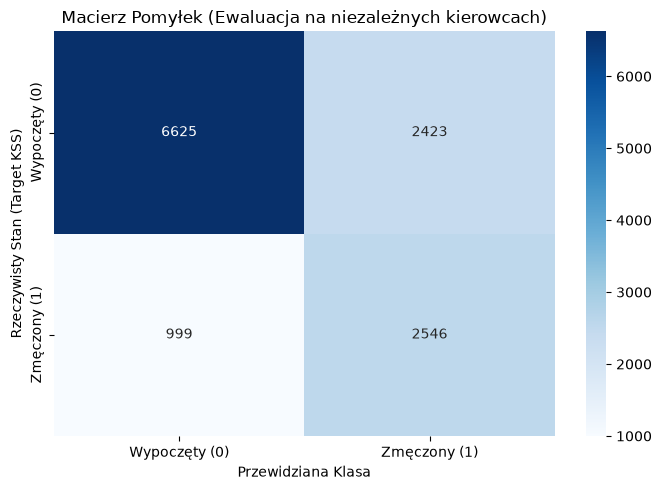

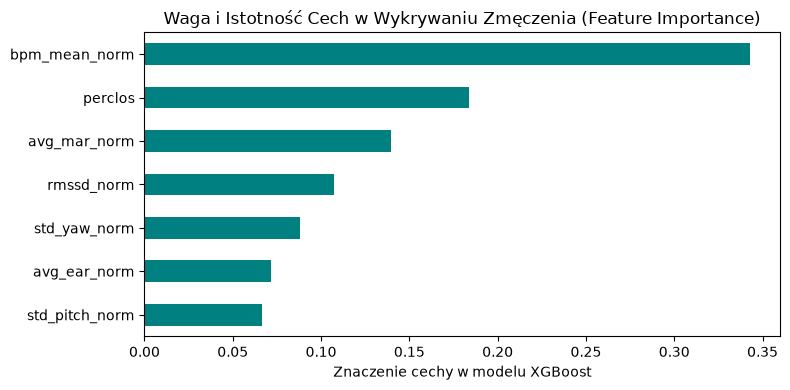

In [ ]:
print("\n=== SZCZEGÓŁOWY RAPORT KLASYFIKACJI ===")
print(
    classification_report(
        y_true_all, y_pred_all, target_names=["Wypoczęty (0)", "Zmęczony (1)"]
    )
)

cm = confusion_matrix(y_true_all, y_pred_all)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Wypoczęty (0)", "Zmęczony (1)"],
    yticklabels=["Wypoczęty (0)", "Zmęczony (1)"],
)
plt.title("Macierz Pomyłek (Ewaluacja na niezależnych kierowcach)")
plt.xlabel("Przewidziana Klasa")
plt.ylabel("Rzeczywisty Stan (Target KSS)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=True)
importances.plot(kind='barh', color='teal')
plt.title("Waga i Istotność Cech w Wykrywaniu Zmęczenia (Feature Importance)")
plt.xlabel("Znaczenie cechy w modelu XGBoost")
plt.tight_layout()
plt.show()